# 08 · Agent evaluation (the business criterion)
**CRISP-DM Phase 5 — Evaluation of the trading agent** · added 2026-11-23 on the `hybrid-version` branch

The business success criterion (`docs/01` §3): *the agent's strategy achieves a higher Sharpe ratio than buy-and-hold
BTC over the out-of-sample test period, net of 0.1% trading fees per side.* This notebook tests it, and also checks the
agent against six simpler strategies, because beating buy-and-hold in a falling market is easy.

| # | Step | Question |
|---|---|---|
| 1 | Protocol | What was chosen on which data, and which windows are truly unseen? |
| 2 | Presets & team | Which settings and which analyst team did the development period pick? |
| 3 | Results | Sharpe, return and drawdown of the agent and every baseline, per window |
| 4 | Significance | Is the Sharpe difference real? (paired block bootstrap) |
| 5 | Business criterion | PASS / FAIL, window by window |
| 6 | Ablation | Which parts of the agent actually help? |
| 7 | Robustness | Fees, slippage, execution delay, rule parameters |
| 8 | Verdict | |

Code: `src/evaluation/portfolio.py`, `agent_backtest.py`, `agent_experiments.py`;
results: `reports/results/agent/` (`python scripts/run_agent_evaluation.py all`). Write-up: `docs/13_agent_evaluation.md`.

<!-- beginner-guide -->

## How to read this notebook (beginner guide)

| Word | Meaning here |
|---|---|
| **Exposure** | Share of the wallet held in BTC (0 = all cash, 1 = all BTC) |
| **Sharpe ratio** | Average return divided by its volatility, per year. Higher = more return per unit of risk. Negative = lost money |
| **Sortino** | Like Sharpe, but only counts the bad (downward) volatility |
| **Max drawdown** | Worst fall from a previous peak of the wallet |
| **Calmar** | Yearly return divided by the max drawdown |
| **Turnover** | How much of the wallet is traded per year (fees grow with it) |
| **Baseline strategy** | A simple rule the agent must beat: hold cash, buy and hold, 50/50, "hold only above the 200-candle average" (SMA200 filter), "hold while EMA20 > EMA50", volatility targeting, or "follow the ML model alone" |
| **Development period** | 2023-01 → 2025-06. The *only* data used to choose settings |
| **Out-of-sample** | Data never used to choose anything: the 2022 bear market and the test window 2025-07-09 → 2026-09-30 |
| **Block bootstrap** | Re-draw whole weeks of returns thousands of times to see how much the Sharpe difference could move by luck |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.agents.config import INTERVAL_PRESETS
from src.evaluation.agent_backtest import DEVELOPMENT, WINDOWS
from src.evaluation.criteria import business_criterion_met
from src.visualization.style import AQUA, BLUE, NEUTRAL, ORANGE, apply_style, save

apply_style()
R = ROOT / "reports" / "results" / "agent"
metrics = pd.read_csv(R / "metrics.csv")
tests = pd.read_csv(R / "sharpe_tests.csv")
curves = pd.read_parquet(R / "equity_curves.parquet")
selection = json.loads((R / "selection.json").read_text())
ORDER = ["2022_bear", "2023_bull", "2025_range", "test"]
IVS = ["1h", "4h", "1D"]
pct = lambda x: f"{x:+.1%}"
print("selected team per interval:", selection["team"])

selected team per interval: {'1D': 'core', '1h': 'core+sentiment', '4h': 'hybrid_lexicon'}


## 1 · Protocol

| Period | Dates | Role |
|---|---|---|
| Development | 2023-01-01 → 2025-06-30 | Choose the presets (smoothing, cooldown, minimum rebalance) and the analyst team, by Sharpe |
| 2022_bear | 2022 | **Out-of-sample** (before development) |
| 2023_bull | 2023 | In-sample: inside the development period |
| 2025_range | 2025 | Half inside the development period |
| test | 2025-07-09 → 2026-09-30 | **Out-of-sample** — the project's test window |

* Prices: the frozen Binance snapshot. Funding rate, Fear & Greed and news: frozen copies in `data/external/`.
* The quant analyst's LightGBM is retrained on candles strictly before each window starts.
* Every strategy, the agent included, trades through the same paper wallet with a 0.1% fee per trade.
  Decisions are made on a candle's close and filled at that close (§7 also tests filling one candle later).

## 2 · Presets and analyst team (development period only)

,conviction_smoothing,min_hold_bars,min_rebalance,sharpe,total_return,trades
interval,,,,,,
1D,3,6,0.25,1.425,1.191,56
1h,12,2,0.35,0.865,0.446,514
4h,24,12,0.25,1.719,1.221,112


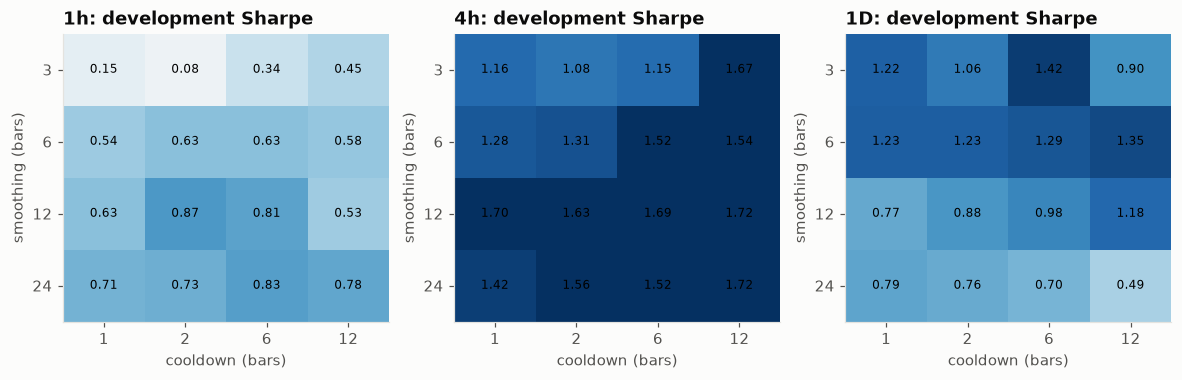

In [3]:
grid = pd.read_csv(R / "preset_tuning.csv")
best = grid.loc[grid.groupby("interval")["sharpe"].idxmax(), ["interval", "conviction_smoothing", "min_hold_bars",
                                                              "min_rebalance", "sharpe", "total_return", "trades"]]
display(best.set_index("interval").round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, iv in zip(axes, IVS):
    g = grid[(grid["interval"] == iv)]
    piv = g.groupby(["conviction_smoothing", "min_hold_bars"])["sharpe"].max().unstack()
    im = ax.imshow(piv.to_numpy(), cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("cooldown (bars)"); ax.set_ylabel("smoothing (bars)"); ax.set_title(f"{iv}: development Sharpe"); ax.grid(False)
    for (i, j), v in np.ndenumerate(piv.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
save(fig, "08_preset_tuning"); plt.show()

The heatmaps show whether the chosen setting sits on a plateau (robust) or on a lone peak (likely overfit).
Below: the analyst teams compared on the same development period.

In [4]:
teams = pd.read_csv(R / "team_selection.csv")
teams.pivot(index="team", columns="interval", values="sharpe")[IVS].round(3)

interval,1h,4h,1D
team,,,
core,0.865,1.719,1.425
core+sentiment,1.042,1.738,1.026
hybrid_lexicon,0.751,1.918,0.955


## 3 · Results on every window

In [5]:
def selected_rows(m):
    keep = m["selected"] | ~m["strategy"].str.startswith("agent:")
    out = m[keep].copy()
    out.loc[out["selected"], "strategy"] = "AGENT"   # the team chosen for that interval (see §2)
    return out

sel = selected_rows(metrics)
sharpe_table = sel.pivot_table(index="strategy", columns=["interval", "window"], values="sharpe")
sharpe_table = sharpe_table.reindex(columns=pd.MultiIndex.from_product([IVS, ORDER]))
sharpe_table.round(2)

1h                                   4h            \
               2022_bear 2023_bull 2025_range  test 2022_bear 2023_bull   
strategy                                                                  
AGENT              -1.54      1.15      -1.99 -1.17     -1.11      1.71   
buy_and_hold       -1.31      2.43       0.07 -0.31     -1.39      2.44   
cash                0.00      0.00       0.00  0.00      0.00      0.00   
ema20_50_cross     -1.46      1.34      -1.51 -0.42     -1.55      2.14   
model_only         -3.20     -2.47      -1.93 -1.05       NaN       NaN   
sma200_filter      -2.52      1.08      -1.86 -1.01     -0.84      2.14   
static_50          -1.45      2.43      -0.04 -0.20     -1.51      2.43   
vol_target         -1.60      2.17      -0.05 -0.43     -1.39      2.24   

                                       1D                             
               2025_range  test 2022_bear 2023_bull 2025_range  test  
strategy                                                              
AGENT                0.72 -0.11     -1.87      1.51       0.65  0.18  
buy_and_hold         0.08 -0.32     -1.34      2.34       0.02 -0.34  
cash                 0.00  0.00      0.00      0.00       0.00  0.00  
ema20_50_cross      -0.31  0.26     -1.91      1.71       0.06 -0.45  
model_only            NaN   NaN       NaN       NaN        NaN   NaN  
sma200_filter       -0.40  0.22      0.00      1.81      -0.42  0.41  
static_50           -0.02 -0.20     -1.43      2.24      -0.08 -0.25  
vol_target          -0.11 -0.54     -1.26      1.59      -0.26 -0.51

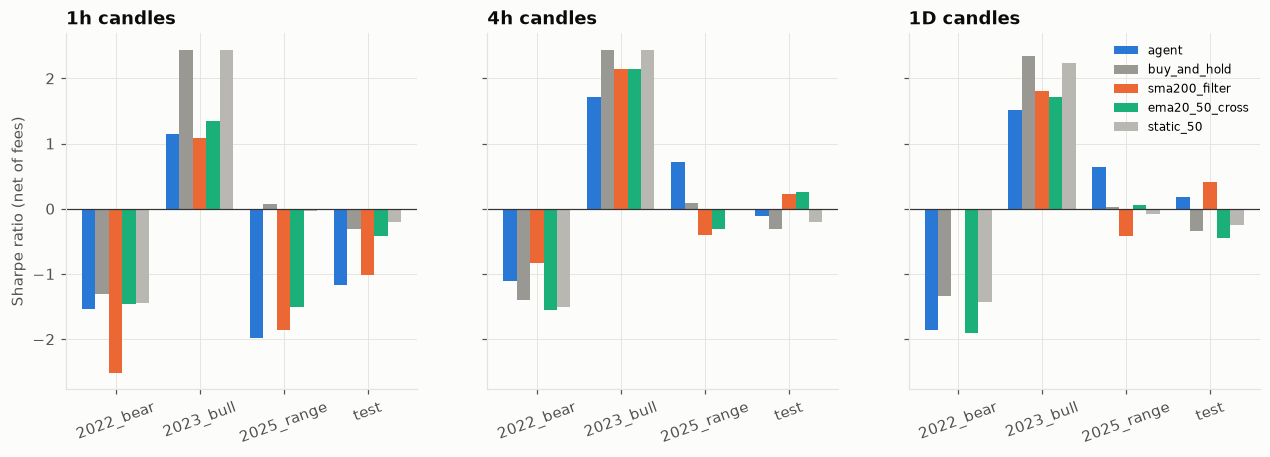

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
names = ["buy_and_hold", "sma200_filter", "ema20_50_cross", "static_50"]
for ax, iv in zip(axes, IVS):
    d = sel[sel["interval"] == iv]
    agent = d[d["strategy"].str.startswith("AGENT")].set_index("window")["sharpe"].reindex(ORDER)
    x, w = np.arange(len(ORDER)), 0.16
    ax.bar(x - 2 * w, agent, w, label="agent", color=BLUE)
    for k, (n, c) in enumerate(zip(names, [NEUTRAL, ORANGE, AQUA, "#b9b7b1"]), start=1):
        v = d[d["strategy"] == n].set_index("window")["sharpe"].reindex(ORDER)
        ax.bar(x + (k - 2) * w, v, w, label=n, color=c)
    ax.axhline(0, color="#333", lw=0.8); ax.set_xticks(x, ORDER, rotation=20); ax.set_title(f"{iv} candles")
axes[0].set_ylabel("Sharpe ratio (net of fees)"); axes[-1].legend(fontsize=8, loc="upper right")
save(fig, "08_sharpe_by_window"); plt.show()

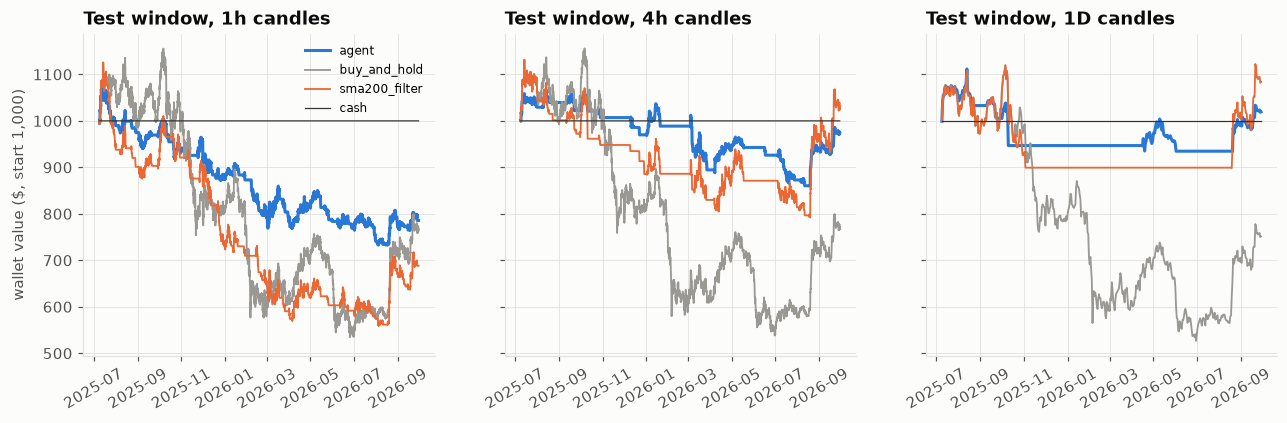

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, iv in zip(axes, IVS):
    chosen = f"agent:{selection['team'][iv]}"
    for name, color, lw in ((chosen, BLUE, 2.0), ("buy_and_hold", NEUTRAL, 1.2), ("sma200_filter", ORANGE, 1.2),
                            ("cash", "#333", 0.8)):
        c = curves[(curves["interval"] == iv) & (curves["window"] == "test") & (curves["strategy"] == name)]
        ax.plot(pd.to_datetime(c["timestamp"]), c["equity"], color=color, lw=lw,
                label="agent" if name == chosen else name)
    ax.set_title(f"Test window, {iv} candles"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("wallet value ($, start 1,000)"); axes[0].legend(fontsize=8)
save(fig, "08_test_equity"); plt.show()

In [8]:
cols = ["total_return", "sharpe", "sortino", "max_drawdown", "calmar", "avg_exposure", "turnover_per_year", "trades", "fees"]
test_table = sel[sel["window"] == "test"].set_index(["interval", "strategy"])[cols]
test_table.round(3)

total_return  sharpe  sortino  max_drawdown  calmar  \
interval strategy                                                              
1h       AGENT                 -0.214  -1.169   -1.663        -0.318  -0.561   
         cash                   0.000   0.000    0.000         0.000   0.000   
         buy_and_hold          -0.233  -0.308   -0.432        -0.537  -0.361   
         static_50             -0.066  -0.197   -0.279        -0.288  -0.187   
         sma200_filter         -0.312  -1.014   -1.477        -0.503  -0.522   
         ema20_50_cross        -0.170  -0.421   -0.615        -0.411  -0.342   
         vol_target            -0.248  -0.427   -0.597        -0.522  -0.397   
         model_only            -0.410  -1.046   -1.453        -0.504  -0.692   
4h       AGENT                 -0.026  -0.106   -0.158        -0.194  -0.110   
         cash                   0.000   0.000    0.000         0.000   0.000   
         buy_and_hold          -0.229  -0.316   -0.441        -0.534  -0.357   
         static_50             -0.065  -0.200   -0.282        -0.287  -0.185   
         sma200_filter          0.031   0.222    0.332        -0.300   0.083   
         ema20_50_cross         0.042   0.258    0.380        -0.292   0.116   
         vol_target            -0.291  -0.540   -0.750        -0.520  -0.470   
1D       AGENT                  0.019   0.183    0.256        -0.160   0.098   
         cash                   0.000   0.000    0.000         0.000   0.000   
         buy_and_hold          -0.249  -0.336   -0.474        -0.530  -0.392   
         static_50             -0.078  -0.251   -0.359        -0.282  -0.228   
         sma200_filter          0.084   0.407    0.630        -0.198   0.344   
         ema20_50_cross        -0.143  -0.451   -0.652        -0.325  -0.364   
         vol_target            -0.297  -0.512   -0.703        -0.535  -0.466   

                         avg_exposure  turnover_per_year  trades     fees  
interval strategy                                                          
1h       AGENT                  0.293            116.320     262  120.657  
         cash                   0.000              0.000       0    0.000  
         buy_and_hold           1.000              0.000       1    1.000  
         static_50              0.470              6.338       2    0.616  
         sma200_filter          0.474            313.672     386  291.286  
         ema20_50_cross         0.492            162.132     200  163.765  
         vol_target             0.938             17.286      94   14.561  
         model_only             0.693            416.328     511  375.596  
4h       AGENT                  0.223             25.882      56   29.215  
         cash                   0.000              0.000       0    0.000  
         buy_and_hold           1.000              0.000       1    1.000  
         static_50              0.469              3.271       2    0.615  
         sma200_filter          0.469             60.290      75   68.022  
         ema20_50_cross         0.481             42.366      53   48.847  
         vol_target             0.948              4.083      20    3.262  
1D       AGENT                  0.191              7.121      17    9.408  
         cash                   0.000              0.000       0    0.000  
         buy_and_hold           1.000              0.000       1    1.000  
         static_50              0.465              1.496       2    0.616  
         sma200_filter          0.346              6.518       9    8.453  
         ema20_50_cross         0.373              8.147      11    9.446  
         vol_target             0.914              1.580       5    1.453

## 4 · Is the difference real? Paired block bootstrap of the Sharpe difference

Both strategies are resampled with the *same* blocks of one week, so the market move they share cancels out.
`p_value` = share of resamples in which the agent does **not** beat the other strategy (one-sided).

In [9]:
t = tests[tests["versus"].isin(["buy_and_hold", "sma200_filter", "agent:core"])].copy()
t["significant (p<0.05)"] = t["p_value"] < 0.05
t.set_index(["interval", "window", "versus"])[["sample", "sharpe_diff", "ci_low", "ci_high", "p_value",
                                                "significant (p<0.05)"]].round(3)

sample  sharpe_diff  \
interval window     versus                                                
1h       2022_bear  buy_and_hold             out-of-sample       -0.233   
                    sma200_filter            out-of-sample        0.979   
                    agent:core               out-of-sample        0.179   
         2023_bull  buy_and_hold   in-sample (development)       -1.284   
                    sma200_filter  in-sample (development)        0.065   
                    agent:core     in-sample (development)        0.166   
         2025_range buy_and_hold       half in development       -2.057   
                    sma200_filter      half in development       -0.125   
                    agent:core         half in development        0.557   
         test       buy_and_hold      out-of-sample (test)       -0.861   
                    sma200_filter     out-of-sample (test)       -0.155   
                    agent:core        out-of-sample (test)        0.354   
4h       2022_bear  buy_and_hold             out-of-sample        0.285   
                    sma200_filter            out-of-sample       -0.268   
                    agent:core               out-of-sample       -0.420   
         2023_bull  buy_and_hold   in-sample (development)       -0.729   
                    sma200_filter  in-sample (development)       -0.425   
                    agent:core     in-sample (development)       -0.017   
         2025_range buy_and_hold       half in development        0.631   
                    sma200_filter      half in development        1.112   
                    agent:core         half in development       -0.237   
         test       buy_and_hold      out-of-sample (test)        0.209   
                    sma200_filter     out-of-sample (test)       -0.328   
                    agent:core        out-of-sample (test)       -0.432   
1D       2022_bear  buy_and_hold             out-of-sample       -0.523   
                    sma200_filter            out-of-sample       -1.865   
         2023_bull  buy_and_hold   in-sample (development)       -0.823   
                    sma200_filter  in-sample (development)       -0.294   
         2025_range buy_and_hold       half in development        0.625   
                    sma200_filter      half in development        1.070   
         test       buy_and_hold      out-of-sample (test)        0.519   
                    sma200_filter     out-of-sample (test)       -0.224   

                                   ci_low  ci_high  p_value  \
interval window     versus                                    
1h       2022_bear  buy_and_hold   -1.874    1.505    0.632   
                    sma200_filter  -0.231    2.231    0.064   
                    agent:core     -0.670    1.134    0.343   
         2023_bull  buy_and_hold   -2.835    0.098    0.968   
                    sma200_filter  -1.010    1.051    0.458   
                    agent:core     -0.170    0.607    0.234   
         2025_range buy_and_hold   -3.606   -0.552    0.996   
                    sma200_filter  -1.471    1.233    0.566   
                    agent:core     -0.185    1.311    0.078   
         test       buy_and_hold   -2.408    0.799    0.876   
                    sma200_filter  -1.506    1.252    0.568   
                    agent:core     -0.557    1.328    0.242   
4h       2022_bear  buy_and_hold   -1.654    2.248    0.386   
                    sma200_filter  -1.500    1.011    0.675   
                    agent:core     -1.625    0.639    0.759   
         2023_bull  buy_and_hold   -2.097    0.671    0.861   
                    sma200_filter  -1.348    0.411    0.850   
                    agent:core     -0.125    0.093    0.658   
         2025_range buy_and_hold   -1.079    2.293    0.241   
                    sma200_filter  -0.041    2.313    0.027   
                    agent:core     -1.021    0.468    0.732   
         test       buy_and_hold   -1.543    1.982  

## 5 · Business criterion: PASS / FAIL

A window passes when the agent's Sharpe beats buy-and-hold's (`src.evaluation.criteria.business_criterion_met`).
A pass is only *convincing* when the bootstrap p-value is below 0.05 **and** the agent also beats the SMA200 filter,
the simplest rule that holds less BTC in a downtrend.

In [10]:
rows = []
for iv in IVS:
    for w in ORDER:
        d = sel[(sel["interval"] == iv) & (sel["window"] == w)].set_index("strategy")["sharpe"]
        agent = d[[i for i in d.index if i.startswith("AGENT")][0]]
        tb = tests[(tests["interval"] == iv) & (tests["window"] == w) & (tests["versus"] == "buy_and_hold")].iloc[0]
        rows.append({"interval": iv, "window": w, "sample": WINDOWS[w][2], "agent_sharpe": agent,
                     "buy_hold_sharpe": d["buy_and_hold"], "sma200_sharpe": d["sma200_filter"],
                     "criterion_met": business_criterion_met(agent, d["buy_and_hold"]),
                     "significant": tb["p_value"] < 0.05, "beats_sma200": agent > d["sma200_filter"]})
verdict = pd.DataFrame(rows).set_index(["interval", "window"])
verdict.round(3)

sample  agent_sharpe  buy_hold_sharpe  \
interval window                                                               
1h       2022_bear             out-of-sample        -1.540           -1.307   
         2023_bull   in-sample (development)         1.145            2.429   
         2025_range      half in development        -1.989            0.068   
         test           out-of-sample (test)        -1.169           -0.308   
4h       2022_bear             out-of-sample        -1.107           -1.392   
         2023_bull   in-sample (development)         1.712            2.441   
         2025_range      half in development         0.716            0.085   
         test           out-of-sample (test)        -0.106           -0.316   
1D       2022_bear             out-of-sample        -1.865           -1.343   
         2023_bull   in-sample (development)         1.513            2.337   
         2025_range      half in development         0.647            0.022   
         test           out-of-sample (test)         0.183           -0.336   

                     sma200_sharpe  criterion_met  significant  beats_sma200  
interval window                                                               
1h       2022_bear          -2.519          False        False          True  
         2023_bull           1.080          False        False          True  
         2025_range         -1.863          False        False         False  
         test               -1.014          False        False         False  
4h       2022_bear          -0.838           True        False         False  
         2023_bull           2.137          False        False         False  
         2025_range         -0.397           True        False          True  
         test                0.222           True        False         False  
1D       2022_bear           0.000          False        False         False  
         2023_bull           1.807          False        False         False  
         2025_range         -0.423           True        False          True  
         test                0.407           True        False         False

In [11]:
oos = verdict[verdict["sample"].str.startswith("out-of-sample")]
print(f"Out-of-sample windows (2022_bear, test) x 3 intervals = {len(oos)} cases")
print(f"  beats buy-and-hold on Sharpe:            {oos['criterion_met'].sum()} / {len(oos)}")
print(f"  ... and significantly (p < 0.05):        {(oos['criterion_met'] & oos['significant']).sum()} / {len(oos)}")
print(f"  ... and also beats the SMA200 filter:    {(oos['criterion_met'] & oos['beats_sma200']).sum()} / {len(oos)}")

Out-of-sample windows (2022_bear, test) x 3 intervals = 6 cases
  beats buy-and-hold on Sharpe:            3 / 6
  ... and significantly (p < 0.05):        0 / 6
  ... and also beats the SMA200 filter:    0 / 6


## 6 · Ablation: remove one component at a time

Each bar is the change in Sharpe when one part is removed from the selected agent (negative = that part helps).
It is shown on the development period (where choices are allowed) and on the two out-of-sample windows.

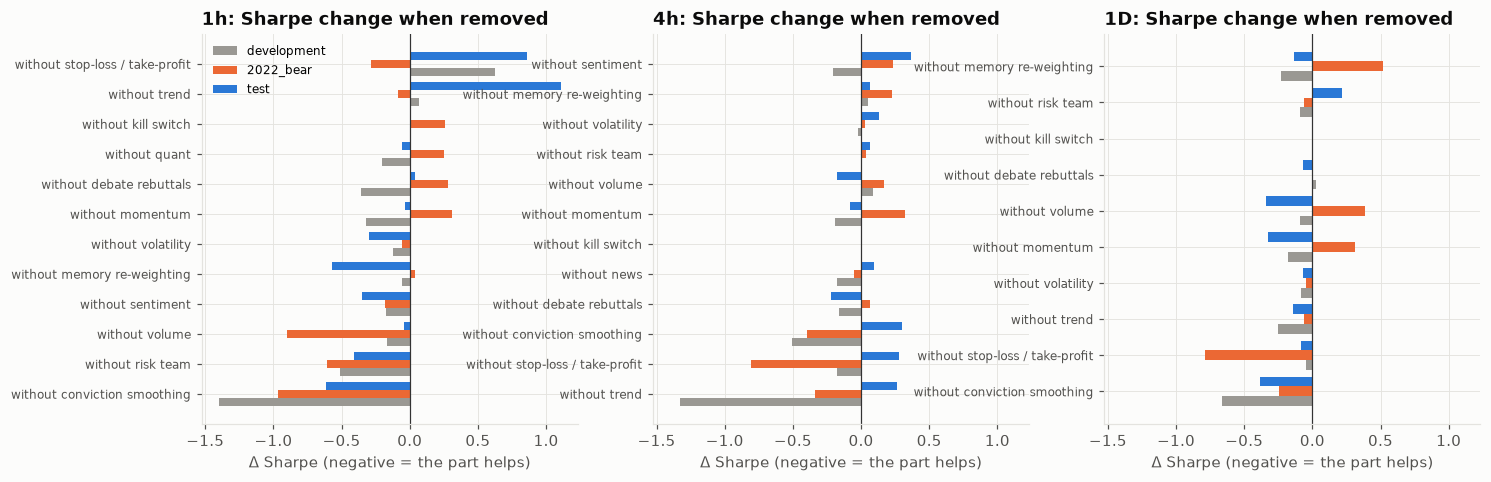

window                                    2022_bear  development   test
interval variant                                                       
1D       full                                 0.000        0.000  0.000
         without conviction smoothing        -0.242       -0.667 -0.384
         without debate rebuttals             0.000        0.025 -0.067
         without kill switch                  0.000        0.000  0.000
         without memory re-weighting          0.516       -0.230 -0.134
         without momentum                     0.314       -0.179 -0.323
         without risk team                   -0.064       -0.088  0.216
         without stop-loss / take-profit     -0.787       -0.048 -0.086
         without trend                       -0.059       -0.252 -0.143
         without volatility                  -0.045       -0.081 -0.067
         without volume                       0.384       -0.087 -0.342
1h       full                                 0.000        0.000  0.000
         without conviction smoothing        -0.967       -1.401 -0.616
         without debate rebuttals             0.282       -0.356  0.036
         without kill switch                  0.257        0.000  0.009
         without memory re-weighting          0.039       -0.055 -0.569
         without momentum                     0.307       -0.320 -0.033
         without quant                        0.251       -0.206 -0.060
         without risk team                   -0.608       -0.513 -0.408
         without sentiment                   -0.179       -0.176 -0.354
         without stop-loss / take-profit     -0.282        0.623  0.859
         without trend                       -0.088        0.067  1.107
         without volatility                  -0.059       -0.121 -0.302
         without volume                      -0.898       -0.169 -0.042
4h       full                                 0.000        0.000  0.000
         without conviction smoothing        -0.399       -0.504  0.300
         without debate rebuttals             0.064       -0.161 -0.220
         without kill switch                  0.000        0.000  0.000
         without memory re-weighting          0.228        0.047  0.069
         without momentum                     0.320       -0.190 -0.082
         without news                        -0.054       -0.180  0.096
         without risk team                    0.039       -0.002  0.067
         without sentiment                    0.231       -0.205  0.364
         without stop-loss / take-profit     -0.806       -0.173  0.280
         without trend                       -0.334       -1.329  0.267
         without volatility                   0.027       -0.025  0.135
         without volume                       0.171        0.085 -0.179

In [12]:
abl = pd.read_csv(R / "ablation.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True)
for ax, iv in zip(axes, IVS):
    d = abl[(abl["interval"] == iv) & (abl["variant"] != "full")]
    piv = d.pivot(index="variant", columns="window", values="sharpe_change")[["development", "2022_bear", "test"]]
    piv = piv.loc[piv.mean(axis=1).sort_values().index]
    y = np.arange(len(piv))
    for k, (w, c) in enumerate(zip(piv.columns, [NEUTRAL, ORANGE, BLUE])):
        ax.barh(y + (k - 1) * 0.27, piv[w], 0.27, color=c, label=w)
    ax.set_yticks(y, piv.index, fontsize=8); ax.axvline(0, color="#333", lw=0.8)
    ax.set_title(f"{iv}: Sharpe change when removed"); ax.set_xlabel("Δ Sharpe (negative = the part helps)")
axes[0].legend(fontsize=8)
save(fig, "08_ablation"); plt.show()
abl.pivot_table(index=["interval", "variant"], columns="window", values="sharpe_change").round(3)

## 7 · Robustness

**Execution.** The agent's exact trades are re-priced under higher fees, slippage and a one-candle execution delay.
**Parameters.** The agent is rerun with one rule parameter changed at a time.

In [13]:
sens = pd.read_csv(R / "sensitivity.csv")
ex = sens[sens["kind"] == "execution"]
ex.pivot_table(index=["interval", "fee", "slippage_bps", "delay_bars"], columns="window", values="sharpe").round(3)

window                                   development   test
interval fee    slippage_bps delay_bars                    
1D       0.0005 0.0          0.0               1.444  0.211
                             1.0               1.191 -1.006
                5.0          0.0               1.425  0.183
                             1.0               1.172 -1.037
                10.0         0.0               1.405  0.155
                             1.0               1.152 -1.067
         0.0010 0.0          0.0               1.425  0.183
                             1.0               1.172 -1.037
                5.0          0.0               1.405  0.155
                             1.0               1.152 -1.067
                10.0         0.0               1.385  0.126
                             1.0               1.133 -1.097
         0.0020 0.0          0.0               1.385  0.126
                             1.0               1.133 -1.097
                5.0          0.0               1.366  0.098
                             1.0               1.113 -1.126
                10.0         0.0               1.346  0.070
                             1.0               1.093 -1.156
1h       0.0005 0.0          0.0               1.307 -0.808
                             1.0               1.431 -0.881
                5.0          0.0               1.042 -1.169
                             1.0               1.166 -1.244
                10.0         0.0               0.777 -1.526
                             1.0               0.901 -1.607
         0.0010 0.0          0.0               1.042 -1.169
                             1.0               1.166 -1.244
                5.0          0.0               0.777 -1.526
                             1.0               0.901 -1.607
                10.0         0.0               0.513 -1.879
                             1.0               0.636 -1.966
         0.0020 0.0          0.0               0.513 -1.879
                             1.0               0.636 -1.966
                5.0          0.0               0.251 -2.228
                             1.0               0.372 -2.323
                10.0         0.0              -0.010 -2.571
                             1.0               0.108 -2.676
4h       0.0005 0.0          0.0               1.982 -0.009
                             1.0               1.948 -0.031
                5.0          0.0               1.918 -0.106
                             1.0               1.887 -0.131
                10.0         0.0               1.854 -0.203
                             1.0               1.825 -0.230
         0.0010 0.0          0.0               1.918 -0.106
                             1.0               1.887 -0.131
                5.0          0.0               1.854 -0.203
                             1.0               1.825 -0.230
                10.0         0.0               1.790 -0.300
                             1.0               1.763 -0.330
         0.0020 0.0          0.0               1.790 -0.300
                             1.0               1.763 -0.330
                5.0          0.0               1.725 -0.396
                             1.0               1.701 -0.429
                10.0         0.0               1.661 -0.492
                             1.0               1.639 -0.528

In [14]:
par = sens[sens["kind"] == "parameter"]
par.pivot_table(index=["interval", "parameter", "value"], columns="window", values="sharpe").round(3)

window                                      development   test
interval parameter            value                           
1D       risk_profile         aggressive          1.121  0.428
                              conservative        0.804 -0.058
                              neutral             1.425  0.183
         smoothing_scale      0.5                 1.246 -0.068
                              1.0                 1.425  0.183
                              2.0                 1.236 -0.170
         stop_atr_mult        1.5                 1.000  0.296
                              2.0                 1.425  0.183
                              3.0                 1.279 -0.019
         take_profit_atr_mult 3.0                 1.277  0.070
                              4.0                 1.425  0.183
                              6.0                 1.181  0.185
         threshold_scale      0.75                1.089 -0.011
                              1.0                 1.425  0.183
                              1.25                1.099  0.231
1h       risk_profile         aggressive          0.705 -0.917
                              conservative        0.788 -1.491
                              neutral             1.042 -1.169
         smoothing_scale      0.5                 0.870 -1.906
                              1.0                 1.042 -1.169
                              2.0                 0.920 -1.043
         stop_atr_mult        1.5                 1.038 -0.778
                              2.0                 1.042 -1.169
                              3.0                 1.028 -0.957
         take_profit_atr_mult 3.0                 0.802 -1.203
                              4.0                 1.042 -1.169
                              6.0                 0.840 -1.064
         threshold_scale      0.75                0.854 -1.055
                              1.0                 1.042 -1.169
                              1.25                0.834 -1.055
4h       risk_profile         aggressive          1.777 -0.228
                              conservative        1.850 -0.270
                              neutral             1.918 -0.106
         smoothing_scale      0.5                 1.685  0.230
                              1.0                 1.918 -0.106
                              2.0                 1.371 -0.280
         stop_atr_mult        1.5                 1.972  0.102
                              2.0                 1.918 -0.106
                              3.0                 1.742  0.245
         take_profit_atr_mult 3.0                 2.015 -0.159
                              4.0                 1.918 -0.106
                              6.0                 1.725 -0.440
         threshold_scale      0.75                1.877 -0.227
                              1.0                 1.918 -0.106
                              1.25                1.828 -0.298

## 8 · Verdict

**Business criterion (Sharpe above buy-and-hold on the test window, net of 0.1% fees): met on 4h and 1D candles,
not met on 1h — but not convincingly.**

1. *Where it passes.* Test window: 4h Sharpe −0.11 vs −0.32 for buy-and-hold, 1D +0.18 vs −0.34. Over the six
   out-of-sample cases (2 windows × 3 candle sizes) the agent beats buy-and-hold in 3.
2. *Not significant.* None of the six differences has a bootstrap p-value below 0.05: 15 months is too short to
   separate a Sharpe gap of ~0.3–0.5 from luck.
3. *Not better than a one-line rule.* The SMA200 filter has the higher Sharpe in 5 of the 6 out-of-sample cases
   (the exception, 1h in 2022, is two heavy losses). The agent's advantage over buy-and-hold is mostly *being out of
   the market in a downtrend*, which the SMA200 filter also does.
4. *What the agent does deliver:* **risk control**. Test-window max drawdown −16% (1D) / −19% (4h) versus −53% for
   buy-and-hold and −20% / −30% for the SMA200 filter, with the explanation of every trade.
5. *1h fails because of fees*: ~260 trades and a turnover of ~116× the wallet in the test window; with 0.2% fees its development Sharpe falls from 1.04 to 0.51.
6. *Fragility.* The 1D result depends on filling at the decision candle's close: filled one day later, test Sharpe
   drops from +0.18 to −1.04. The 4h result barely moves (−0.11 → −0.13).
7. *Team choice is noise-level.* The development period picked `hybrid_lexicon` on 4h (Sharpe 1.92 vs 1.72 for
   `core`), yet `core` did better on the test window (0.33 vs −0.11). News, sentiment and memory change the Sharpe by
   less than ±0.4 in the ablation, in both directions; only conviction smoothing and the stop/risk layer help
   consistently.

Full discussion: `docs/13_agent_evaluation.md`.